# Market Data Validation and Calendar Alignment

This notebook validates four datasets:
Bitcoin prices in USD, the S&P 500 price index,
the US 10-year Treasury yield, and Google search
interest in bitcoin.

The datasets come from three sources:
Yahoo Finance, the Federal Reserve Board through FRED,
and Google Trends.

We distinguish missing values from dates absent because
of different trading calendars. No values are imputed
at this stage.

Daily date labels are retained as supplied.
Matching dates does not imply simultaneous observations.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

raw_dir = Path("../data/raw")


def load_market_file(filename, value_name):
    data = pd.read_csv(raw_dir / filename)

    # Preserve the provider's calendar date.
    # These daily labels are not exact closing timestamps.
    data["date"] = pd.to_datetime(
        data["Date"].str.slice(0, 10),
        format="%Y-%m-%d",
        errors="raise"
    )

    data[value_name] = pd.to_numeric(
        data["Close"], errors="raise"
    )

    return (
        data[["date", value_name]]
        .sort_values("date")
        .reset_index(drop=True)
    )


btc = load_market_file(
    "btc_usd_yahoo_2018_2026.csv", "btc_close_usd"
)

sp500 = load_market_file(
    "sp500_yahoo_2018_2026.csv", "sp500_close"
)

treasury = pd.read_csv(
    raw_dir / "treasury_10y_fred.csv",
    na_values=["."]
)

treasury["date"] = pd.to_datetime(
    treasury["date"], errors="raise"
)
treasury["treasury_10y_percent"] = pd.to_numeric(
    treasury["treasury_10y_percent"], errors="raise"
)
treasury = treasury.sort_values("date").reset_index(drop=True)

checks = []

for name, data, column in [
    ("Bitcoin", btc, "btc_close_usd"),
    ("S&P 500", sp500, "sp500_close"),
    ("Treasury 10Y", treasury, "treasury_10y_percent")
]:
    values = data[column]

    checks.append({
        "dataset": name,
        "rows": len(data),
        "first_date": data["date"].min(),
        "last_date": data["date"].max(),
        "missing_dates": data["date"].isna().sum(),
        "duplicate_dates": data["date"].duplicated().sum(),
        "missing_values": values.isna().sum(),
        "infinite_values": np.isinf(values).sum()
    })

quality_report = pd.DataFrame(checks)
display(quality_report)

,dataset,rows,first_date,last_date,missing_dates,duplicate_dates,missing_values,infinite_values
0,Bitcoin,3243,2018-01-01,2026-11-17,0,0,0,0
1,S&P 500,2232,2018-01-02,2026-11-17,0,0,0,0
2,Treasury 10Y,2315,2018-01-02,2026-11-16,0,0,97,0


In [2]:
trends = pd.read_csv(
    raw_dir / "google_trends_bitcoin.csv",
    skiprows=2
)

trends.columns = ["month", "interest_raw"]

trends["month"] = pd.to_datetime(
    trends["month"], format="%Y-%m", errors="raise"
)

trends = trends.loc[
    trends["month"].between("2018-01-01", "2026-10-01")
].copy()

# "<1" is an interval, not an exact zero.
trends["below_one"] = trends["interest_raw"].astype(str).eq("<1")

trends["search_interest"] = pd.to_numeric(
    trends["interest_raw"].replace("<1", np.nan),
    errors="raise"
)

trends = trends.reset_index(drop=True)

print("Months:", len(trends))
print("First month:", trends["month"].min())
print("Last month:", trends["month"].max())
print("Values below 1:", trends["below_one"].sum())
print("Duplicate months:", trends["month"].duplicated().sum())

display(trends.head())

Months: 106
First month: 2018-01-01 00:00:00
Last month: 2026-10-01 00:00:00
Values below 1: 0
Duplicate months: 0


,month,interest_raw,below_one,search_interest
0,2018-01-01,55,False,55
1,2018-02-01,40,False,40
2,2018-03-01,24,False,24
3,2018-04-01,18,False,18
4,2018-05-01,14,False,14


## Google Trends — Bitcoin search interest

Source: https://trends.google.com/trends/
Search term: bitcoin.
Geography: Worldwide.
Category: All categories.
Downloaded file: multiTimeline.csv.
Frequency: monthly.

The exported index is normalized over the original
requested period, January 2004–November 2026.
Filtering to 2018 onward does not renormalize it.

We exclude November 2026 because it was incomplete
at download time. Values marked "<1" are retained
as a flag and treated as unknown numeric values.

Search interest is a relative index, not an absolute
search count or a measure of positive sentiment.

In [3]:
calendar_rows = []
calendar_details = {}

for name, data, column in [
    ("Bitcoin", btc, "btc_close_usd"),
    ("S&P 500", sp500, "sp500_close"),
    ("Treasury 10Y", treasury, "treasury_10y_percent")
]:
    dates = pd.DatetimeIndex(data["date"])

    calendar = pd.date_range(
        dates.min(), dates.max(), freq="D"
    )

    absent_dates = calendar.difference(dates)
    missing_value_dates = pd.DatetimeIndex(
        data.loc[data[column].isna(), "date"]
    )

    calendar_rows.append({
        "dataset": name,
        "calendar_days": len(calendar),
        "recorded_dates": dates.nunique(),
        "absent_weekend_dates": (absent_dates.dayofweek >= 5).sum(),
        "absent_weekday_dates": (absent_dates.dayofweek < 5).sum(),
        "rows_with_missing_values": len(missing_value_dates)
    })

    calendar_details[name] = {
        "absent_dates": absent_dates,
        "missing_value_dates": missing_value_dates
    }

calendar_report = pd.DataFrame(calendar_rows)
display(calendar_report)

for name, details in calendar_details.items():
    print(f"\n{name} — first absent weekdays:")
    absent = details["absent_dates"]
    print(absent[absent.dayofweek < 5][:10])

    print("First dates with missing values:")
    print(details["missing_value_dates"][:10])

,dataset,calendar_days,recorded_dates,absent_weekend_dates,absent_weekday_dates,rows_with_missing_values
0,Bitcoin,3243,3243,0,0,0
1,S&P 500,3242,2232,926,84,0
2,Treasury 10Y,3241,2315,926,0,97



Bitcoin — first absent weekdays:
DatetimeIndex([], dtype='datetime64[us]', freq='D')
First dates with missing values:
DatetimeIndex([], dtype='datetime64[us]', name='date', freq=None)

S&P 500 — first absent weekdays:
DatetimeIndex(['2018-01-15', '2018-02-19', '2018-03-30', '2018-05-28',
               '2018-07-04', '2018-09-03', '2018-11-22', '2018-12-05',
               '2018-12-25', '2019-01-01'],
              dtype='datetime64[us]', freq=None)
First dates with missing values:
DatetimeIndex([], dtype='datetime64[us]', name='date', freq=None)

Treasury 10Y — first absent weekdays:
DatetimeIndex([], dtype='datetime64[us]', freq=None)
First dates with missing values:
DatetimeIndex(['2018-01-15', '2018-02-19', '2018-03-30', '2018-05-28',
               '2018-07-04', '2018-09-03', '2018-10-08', '2018-11-12',
               '2018-11-22', '2018-12-05'],
              dtype='datetime64[us]', name='date', freq=None)


## Calendar coverage and missing observations

We distinguish dates absent from each dataset from
recorded dates whose values are missing.

Weekend absences can reflect market calendars.
Absent weekdays and missing values require further
checks against the relevant publication or trading calendar.
A weekday is not necessarily a trading day.

Each dataset is checked within its own observed date range.
Differences at the start or end of coverage are therefore
not counted as internal calendar gaps.

We do not insert zero returns, interpolate prices,
or forward-fill yields at this stage.
Daily date labels do not imply simultaneous market closes.

In [4]:
def monthly_last_observation(data, value_column, date_column_name):
    valid = (
        data[["date", value_column]]
        .dropna(subset=[value_column])
        .sort_values("date")
        .copy()
    )

    valid["month"] = (
        valid["date"].dt.to_period("M").dt.to_timestamp()
    )

    counts = valid.groupby("month").size()

    monthly = (
        valid.groupby("month", sort=True)
        .tail(1)
        .rename(columns={"date": date_column_name})
        .set_index("month")
    )

    monthly[f"{value_column}_observations"] = counts

    return monthly


btc_monthly = monthly_last_observation(
    btc, "btc_close_usd", "btc_last_date"
)

sp500_monthly = monthly_last_observation(
    sp500, "sp500_close", "sp500_last_date"
)

treasury_monthly = monthly_last_observation(
    treasury, "treasury_10y_percent", "treasury_last_date"
)

# Use complete months covered by the Trends analysis
months = pd.date_range(
    "2018-01-01", "2026-10-01", freq="MS", name="month"
)

monthly = pd.DataFrame(index=months)

for table in [btc_monthly, sp500_monthly, treasury_monthly]:
    monthly = monthly.join(table, validate="one_to_one")

monthly = monthly.join(
    trends.set_index("month")[["search_interest"]],
    validate="one_to_one"
)

print("Monthly rows:", len(monthly))
print("\nMissing values in analytical columns:")

analysis_columns = [
    "btc_close_usd",
    "sp500_close",
    "treasury_10y_percent",
    "search_interest"
]

display(monthly[analysis_columns].isna().sum())

display(
    monthly[
        [
            "btc_last_date", "btc_close_usd",
            "sp500_last_date", "sp500_close",
            "treasury_last_date", "treasury_10y_percent",
            "search_interest"
        ]
    ].head()
)

Monthly rows: 106

Missing values in analytical columns:


btc_close_usd           0
sp500_close             0
treasury_10y_percent    0
search_interest         0
dtype: int64

,btc_last_date,btc_close_usd,sp500_last_date,sp500_close,treasury_last_date,treasury_10y_percent,search_interest
month,,,,,,,
2018-01-01,2018-01-31,10221.099609,2018-01-31,2823.810059,2018-01-31,2.72,55
2018-02-01,2018-02-28,10397.900391,2018-02-28,2713.830078,2018-02-28,2.87,40
2018-03-01,2018-03-31,6973.529785,2018-03-29,2640.870117,2018-03-29,2.74,24
2018-04-01,2018-04-30,9240.549805,2018-04-30,2648.050049,2018-04-30,2.95,18
2018-05-01,2018-05-31,7494.169922,2018-05-31,2705.270020,2018-05-31,2.83,14


## Monthly alignment across sources

Google Trends determines the monthly frequency of this table.
We retain complete months from January 2018 to October 2026.

For Bitcoin and S&P 500, we select the last available closing
price in each month. For Treasury yields, we select the last
non-missing observation. We retain observation dates and
counts to make differences in coverage visible.

Google Trends represents search interest over the month,
whereas prices and yields are end-of-month observations.
They are not simultaneous measurements.

No missing values are filled during the merge.
Monthly availability does not establish complete daily coverage:
an earlier observation can become the last available value
if a month-end observation is missing.

This table supports descriptive analysis. Same-month search
interest cannot be treated as information available at the
beginning of that month in a forecasting model.

In [5]:
# Returns between consecutive observed month-end prices
for prefix, price_column in [
    ("btc", "btc_close_usd"),
    ("sp500", "sp500_close")
]:
    prices = monthly[price_column]

    if prices.dropna().le(0).any():
        raise ValueError(f"Non-positive prices in {price_column}")

    monthly[f"{prefix}_return_pct"] = (
        prices.pct_change(fill_method=None) * 100
    )

    monthly[f"{prefix}_log_return_pct"] = (
        np.log(prices / prices.shift(1)) * 100
    )

# Yield changes: percentage points, not percentage returns
monthly["treasury_change_pp"] = (
    monthly["treasury_10y_percent"].diff()
)

change_columns = [
    "btc_return_pct",
    "sp500_return_pct",
    "btc_log_return_pct",
    "sp500_log_return_pct",
    "treasury_change_pp"
]

display(monthly[change_columns].head().round(3))
display(monthly[change_columns].describe().round(3))

,btc_return_pct,sp500_return_pct,btc_log_return_pct,sp500_log_return_pct,treasury_change_pp
month,,,,,
2018-01-01,NaN,NaN,NaN,NaN,NaN
2018-02-01,1.730,-3.895,1.715,-3.973,0.15
2018-03-01,-32.933,-2.688,-39.948,-2.725,-0.13
2018-04-01,32.509,0.272,28.148,0.272,0.21
2018-05-01,-18.899,2.161,-20.948,2.138,-0.12


,btc_return_pct,sp500_return_pct,btc_log_return_pct,sp500_log_return_pct,treasury_change_pp
count,105.000,105.000,105.000,105.000,105.000
mean,3.672,1.054,1.929,0.940,0.021
std,19.134,4.691,18.461,4.695,0.257
min,-37.769,-12.512,-47.431,-13.367,-0.520
25%,-7.612,-1.424,-7.918,-1.434,-0.130
50%,1.730,1.792,1.715,1.777,0.010
75%,12.239,3.712,11.546,3.645,0.180
max,60.249,12.684,47.156,11.942,0.680


## Monthly returns and yield changes

Simple percentage returns are calculated as:

$$
R_t = 100\left(\frac{P_t}{P_{t-1}} - 1\right)
$$

Logarithmic returns are calculated as:

$$
r_t = 100\ln\left(\frac{P_t}{P_{t-1}}\right)
$$

Treasury yield changes are measured in percentage points:

$$
\Delta y_t = y_t - y_{t-1}
$$

For example, a yield increase from 4.0% to 4.2%
equals 0.2 percentage points, or 20 basis points.

January 2018 has no calculated return or yield change
because December 2017 is outside the loaded data.
These initial missing values are expected and are not filled.

Returns use each market's last available monthly observation,
so their exact measurement endpoints can differ.
S&P 500 returns exclude dividend reinvestment.

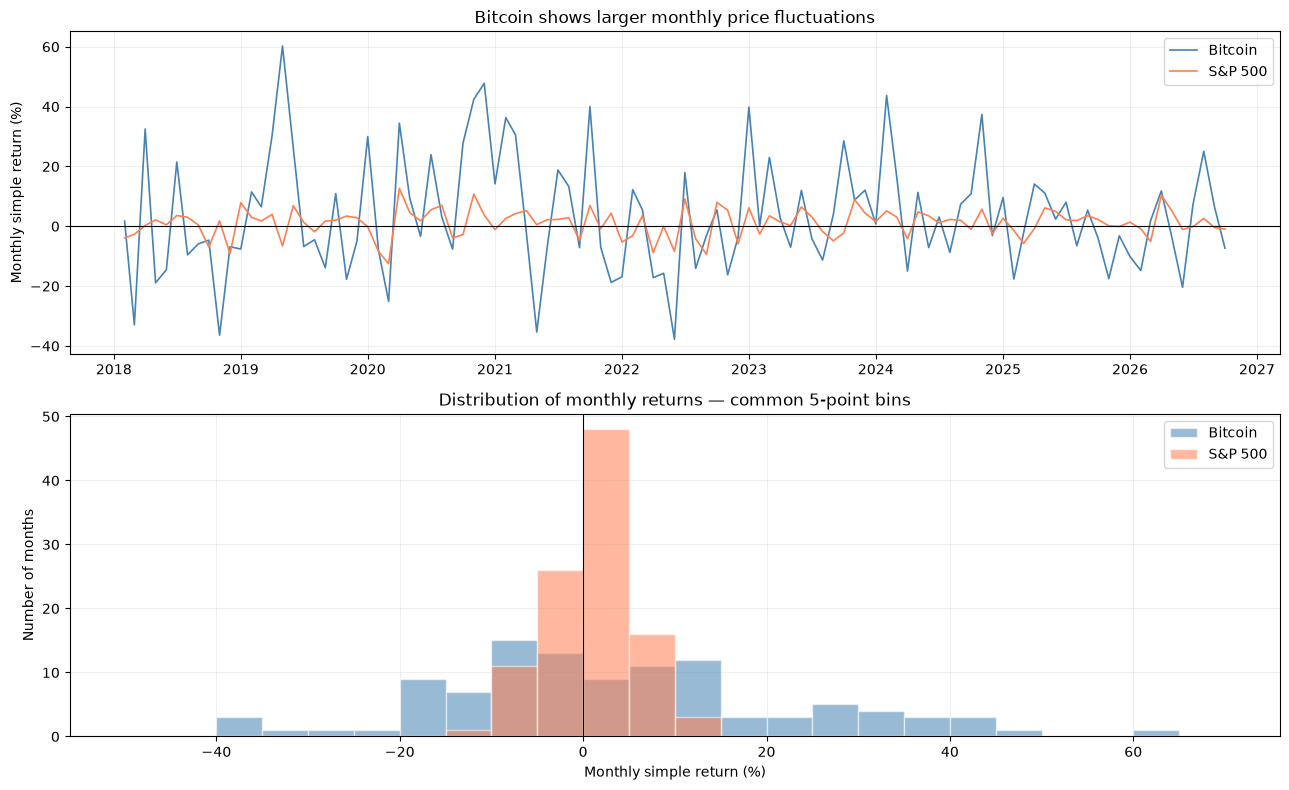

In [6]:
import matplotlib.pyplot as plt

returns = monthly[
    ["btc_return_pct", "sp500_return_pct"]
].dropna()

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

for column, label, color in [
    ("btc_return_pct", "Bitcoin", "steelblue"),
    ("sp500_return_pct", "S&P 500", "coral")
]:
    axes[0].plot(
        returns.index, returns[column],
        label=label, color=color, linewidth=1.2
    )

    axes[1].hist(
        returns[column],
        bins=np.arange(-50, 71, 5),
        alpha=0.55,
        label=label,
        color=color,
        edgecolor="white"
    )

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Bitcoin shows larger monthly price fluctuations")
axes[0].set_ylabel("Monthly simple return (%)")

axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Distribution of monthly returns — common 5-point bins")
axes[1].set_xlabel("Monthly simple return (%)")
axes[1].set_ylabel("Number of months")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Initial findings — monthly return variability

Across 105 monthly intervals, Bitcoin's simple returns
have a sample standard deviation of 19.13%, compared
with 4.69% for the S&P 500 — approximately 4.1 times larger.

Bitcoin's observed monthly returns range from −37.77%
to +60.25%, versus −12.51% to +12.68% for the S&P 500.
These are sample extremes, not bounds on future outcomes.

Arithmetic mean monthly returns are 3.67% and 1.05%,
respectively. They are not cumulative or compounded returns.

The Treasury yield's mean monthly change is 0.021
percentage points, with a standard deviation of 0.257
percentage points. These units differ from asset returns.

These summaries describe the selected period.
They do not establish stable volatility, normal return
distributions or predictive relationships.

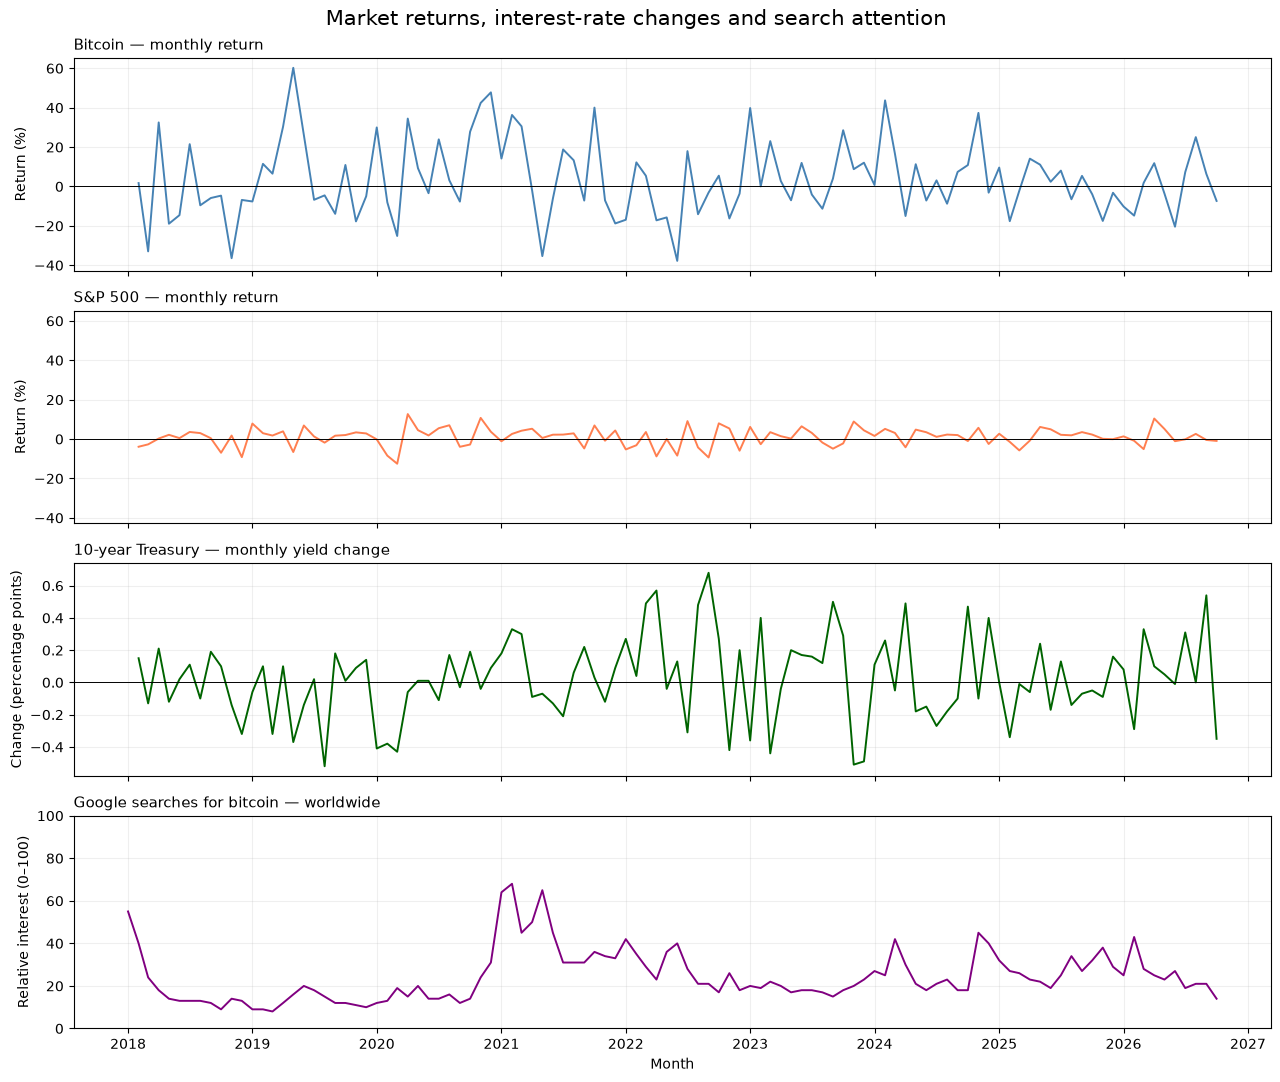

In [7]:
fig, axes = plt.subplots(
    4, 1, figsize=(13, 11), sharex=True
)

panels = [
    ("btc_return_pct", "Bitcoin — monthly return", "Return (%)", "steelblue"),
    ("sp500_return_pct", "S&P 500 — monthly return", "Return (%)", "coral"),
    ("treasury_change_pp", "10-year Treasury — monthly yield change",
     "Change (percentage points)", "darkgreen"),
    ("search_interest", "Google searches for bitcoin — worldwide",
     "Relative interest (0–100)", "purple")
]

for ax, (column, title, ylabel, color) in zip(axes, panels):
    ax.plot(
        monthly.index,
        monthly[column],
        color=color,
        linewidth=1.4
    )

    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

    if column != "search_interest":
        ax.axhline(0, color="black", linewidth=0.7)
    else:
        ax.set_ylim(0, 100)

# Same scale for the two return panels
return_values = monthly[
    ["btc_return_pct", "sp500_return_pct"]
].to_numpy()

lower = np.nanmin(return_values) - 5
upper = np.nanmax(return_values) + 5

axes[0].set_ylim(lower, upper)
axes[1].set_ylim(lower, upper)

axes[-1].set_xlabel("Month")

fig.suptitle(
    "Market returns, interest-rate changes and search attention",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Four series from three independent sources

Separate panels preserve each variable's units.
Bitcoin and S&P 500 returns share the same vertical scale
to allow a fair visual comparison of their fluctuations.

Treasury yield changes are measured in percentage points.
Google Trends measures relative search interest,
not returns, search counts or investor sentiment.

The shared horizontal axis supports comparison over time.
Visual coincidence does not establish correlation,
predictive value or causation.

The month labels identify calendar months, not the exact
time at which all observations became available.

Common monthly observations: 105


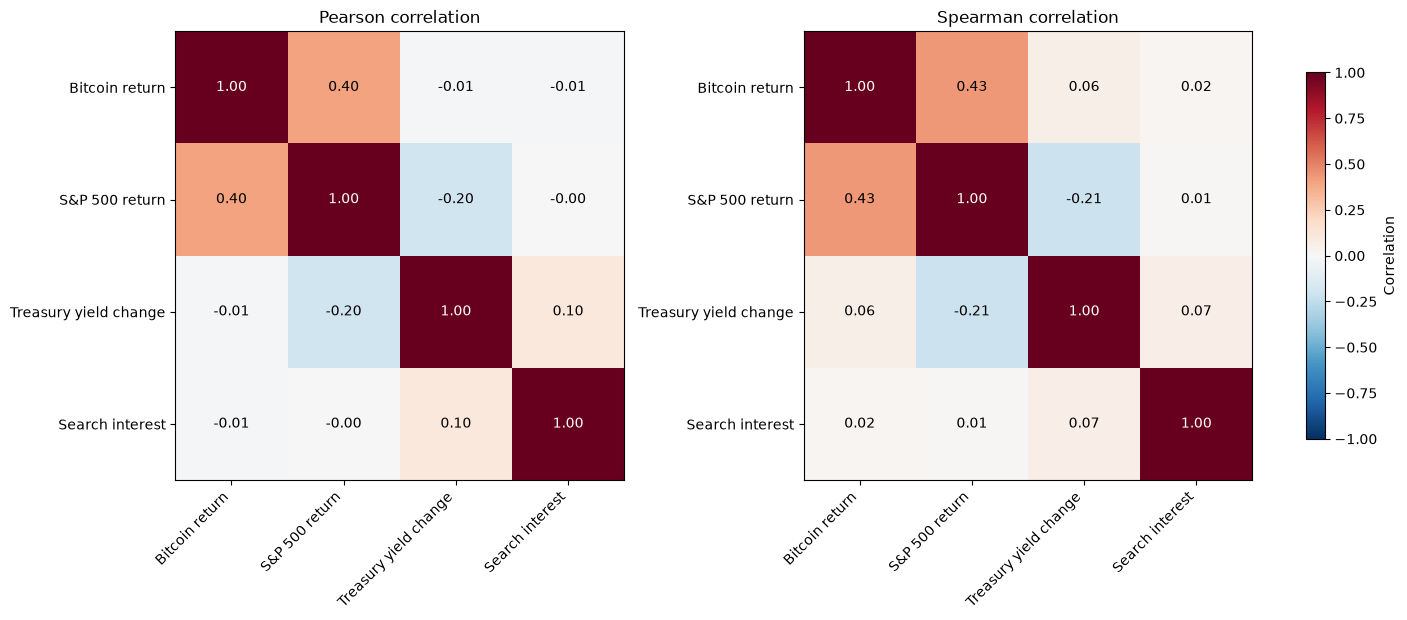

Pearson:


,Bitcoin return,S&P 500 return,Treasury yield change,Search interest
Bitcoin return,1.000,0.400,-0.011,-0.010
S&P 500 return,0.400,1.000,-0.197,-0.004
Treasury yield change,-0.011,-0.197,1.000,0.103
Search interest,-0.010,-0.004,0.103,1.000


Spearman:


,Bitcoin return,S&P 500 return,Treasury yield change,Search interest
Bitcoin return,1.000,0.433,0.058,0.016
S&P 500 return,0.433,1.000,-0.211,0.011
Treasury yield change,0.058,-0.211,1.000,0.069
Search interest,0.016,0.011,0.069,1.000


In [8]:
correlation_data = monthly[
    [
        "btc_return_pct",
        "sp500_return_pct",
        "treasury_change_pp",
        "search_interest"
    ]
].dropna().rename(columns={
    "btc_return_pct": "Bitcoin return",
    "sp500_return_pct": "S&P 500 return",
    "treasury_change_pp": "Treasury yield change",
    "search_interest": "Search interest"
})

print("Common monthly observations:", len(correlation_data))

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6), layout="constrained"
)

for ax, method in zip(axes, ["pearson", "spearman"]):
    correlations = correlation_data.corr(method=method)

    image = ax.imshow(
        correlations,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(len(correlations)))
    ax.set_yticks(range(len(correlations)))
    ax.set_xticklabels(
        correlations.columns, rotation=45, ha="right"
    )
    ax.set_yticklabels(correlations.index)
    ax.set_title(f"{method.title()} correlation")

    for row in range(len(correlations)):
        for col in range(len(correlations)):
            value = correlations.iloc[row, col]
            ax.text(
                col, row, f"{value:.2f}",
                ha="center", va="center",
                color="white" if abs(value) > 0.6 else "black"
            )

fig.colorbar(
    image, ax=axes.tolist(),
    label="Correlation", shrink=0.8
)

plt.show()

print("Pearson:")
display(correlation_data.corr(method="pearson").round(3))

print("Spearman:")
display(correlation_data.corr(method="spearman").round(3))

## Exploratory contemporaneous correlations

Pearson correlation measures linear association.
Spearman correlation measures association between ranks
and is less sensitive to the magnitude of extreme values.

All coefficients use the same complete monthly observations.
Search interest is analyzed as an index level; Treasury
yields are analyzed as changes in percentage points.

These are descriptive same-month associations, not evidence
of causation or forecasting ability. Search interest can
respond to both price increases and price declines.

### Initial correlation findings

Across 105 common monthly observations, Bitcoin and
S&P 500 returns show a positive association:
Pearson r = 0.400 and Spearman rho = 0.433.

S&P 500 returns have a weak negative association with
Treasury yield changes (−0.197 and −0.211).
Bitcoin returns have near-zero correlations with
Treasury yield changes.

Search interest has near-zero correlations with signed
market returns. This does not establish independence:
attention may relate to movement magnitude, nonlinear
patterns or lagged relationships.

These are exploratory sample associations. Their stability
over time and sensitivity to unusual months remain untested.

,pearson,spearman
Signed Bitcoin return,-0.01,0.016
Absolute Bitcoin return,0.17,0.101


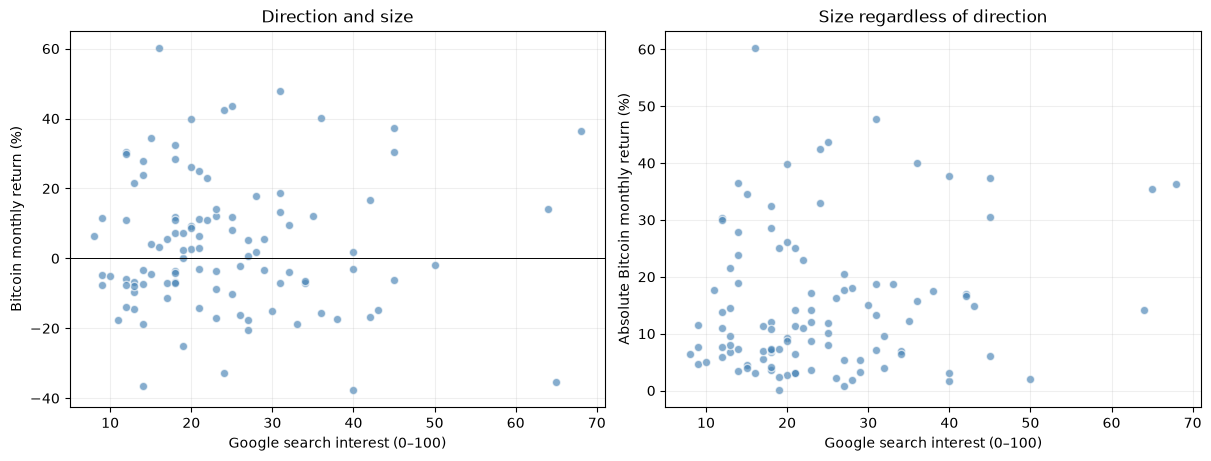

In [9]:
attention = monthly[
    ["btc_return_pct", "search_interest"]
].dropna().copy()

attention["absolute_return_pct"] = (
    attention["btc_return_pct"].abs()
)

results = pd.DataFrame({
    method: [
        attention["search_interest"].corr(
            attention["btc_return_pct"], method=method
        ),
        attention["search_interest"].corr(
            attention["absolute_return_pct"], method=method
        )
    ]
    for method in ["pearson", "spearman"]
}, index=["Signed Bitcoin return", "Absolute Bitcoin return"])

display(results.round(3))

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), layout="constrained"
)

for ax, column, title in [
    (axes[0], "btc_return_pct", "Direction and size"),
    (axes[1], "absolute_return_pct", "Size regardless of direction")
]:
    ax.scatter(
        attention["search_interest"],
        attention[column],
        color="steelblue",
        alpha=0.65,
        edgecolors="white"
    )

    ax.set_title(title)
    ax.set_xlabel("Google search interest (0–100)")
    ax.set_ylabel(
        "Bitcoin monthly return (%)"
        if column == "btc_return_pct"
        else "Absolute Bitcoin monthly return (%)"
    )
    ax.grid(alpha=0.2)

axes[0].axhline(0, color="black", linewidth=0.7)

plt.show()

## Search attention and movement magnitude

We compare search interest with signed Bitcoin returns
and their absolute values.

Absolute monthly return measures the magnitude of the
net month-end movement. It does not measure all price
fluctuations within the month and is not equivalent
to realized volatility.

These exploratory comparisons use the same months.
Any association may reflect attention responding to
market movements, shared influences or other mechanisms.
It does not establish causation or predictive ability.

### Findings — search attention and Bitcoin movements

Search interest has near-zero correlations with signed
monthly Bitcoin returns (Pearson −0.010; Spearman 0.016).

Its association with absolute monthly returns is positive
but weak (Pearson 0.170; Spearman 0.101).
The scatter plot shows substantial dispersion.

These results provide limited descriptive support for
a same-month association between attention and net movement
magnitude. They do not establish statistical significance,
causation or forecasting ability.

Absolute monthly returns can hide large within-month
fluctuations that cancel out by month-end.
A subsequent analysis will examine volatility calculated
from daily returns and the stability of relationships
over time.

## Next steps: hypothesis testing and uncertainty

The exploratory analysis found a Pearson correlation of approximately
0.40 between monthly Bitcoin and S&P 500 returns across 105 common months.

Our primary question is:
Is this positive association consistent across time, and how uncertain
is the estimated correlation?

- Null hypothesis (H₀): the population correlation is zero.
- Alternative hypothesis (H₁): the population correlation is not zero.
- Planned significance level: α = 0.05.

Before selecting a test, we will examine outliers, serial dependence,
and changes in the relationship over time. We will estimate a confidence
interval using a method that accounts for time dependence where necessary.

Additional analyses will be treated as exploratory. We will report
effect sizes and uncertainty, rather than relying only on p-values.

These analyses assess association, not causation or forecasting ability.
The hypotheses were formulated after inspecting the data, so the results
must be interpreted as exploratory rather than independent confirmation.

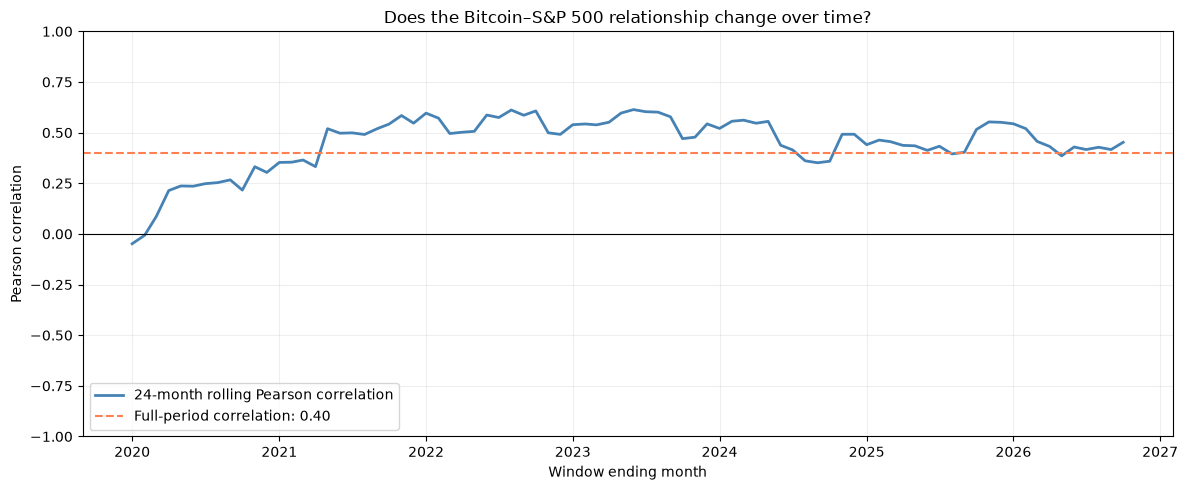

Complete 24-month windows: 82


count    82.000
mean      0.449
std       0.135
min      -0.049
25%       0.397
50%       0.491
75%       0.546
max       0.614
Name: rolling_correlation, dtype: float64

In [10]:
# Preserve the monthly calendar, including any missing observations.
paired_returns = monthly[
    ["btc_return_pct", "sp500_return_pct"]
].sort_index()

window = 24

rolling_correlation = (
    paired_returns["btc_return_pct"]
    .rolling(window=window, min_periods=window)
    .corr(paired_returns["sp500_return_pct"])
)

overall_correlation = paired_returns["btc_return_pct"].corr(
    paired_returns["sp500_return_pct"]
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rolling_correlation.index,
    rolling_correlation,
    color="steelblue",
    linewidth=2,
    label="24-month rolling Pearson correlation"
)

ax.axhline(
    overall_correlation,
    color="coral",
    linestyle="--",
    label=f"Full-period correlation: {overall_correlation:.2f}"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set(
    title="Does the Bitcoin–S&P 500 relationship change over time?",
    xlabel="Window ending month",
    ylabel="Pearson correlation",
    ylim=(-1, 1)
)

ax.legend(loc="lower left")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Complete 24-month windows:", rolling_correlation.notna().sum())
display(
    rolling_correlation.dropna()
    .rename("rolling_correlation")
    .describe()
    .round(3)
)

## Stability of the Bitcoin–S&P 500 association

We calculate Pearson correlations over trailing 24-month windows.
Each estimate is positioned at the final month of its window.

The two-year window balances local detail with the number of
observations per estimate. It is an exploratory choice.

Adjacent windows share 23 months, so their estimates are strongly
dependent. This plot describes variation in the estimated association;
it does not by itself demonstrate statistically significant changes.

The dashed line shows the full-period correlation as a reference.

### Findings — rolling correlations

Across 82 complete 24-month windows, Pearson correlations
between Bitcoin and S&P 500 monthly returns range from
−0.049 to 0.614, with a median of 0.491.

The earliest estimates are close to zero, while later
windows generally show a stronger positive association.
The full-period correlation of 0.400 therefore hides
variation in the estimated relationship over time.

These changes may reflect both changes in market relationships
and sampling variability. Adjacent windows share 23 observations,
so the 82 estimates are not independent.

This descriptive analysis does not establish statistically
significant structural change, causation or predictive ability.

,Bitcoin return,S&P 500 return,Absolute Bitcoin return,Absolute S&P 500 return
Lag (months),,,,
1,0.154,-0.133,0.018,0.246
2,-0.002,-0.144,0.096,0.030
3,0.130,0.047,-0.001,0.095
4,-0.017,-0.015,-0.075,-0.005
5,-0.095,-0.033,0.017,0.028
6,-0.079,-0.092,0.009,0.007
7,-0.061,0.192,0.136,-0.118
8,0.141,0.095,0.074,-0.054
9,-0.041,-0.151,0.051,0.017


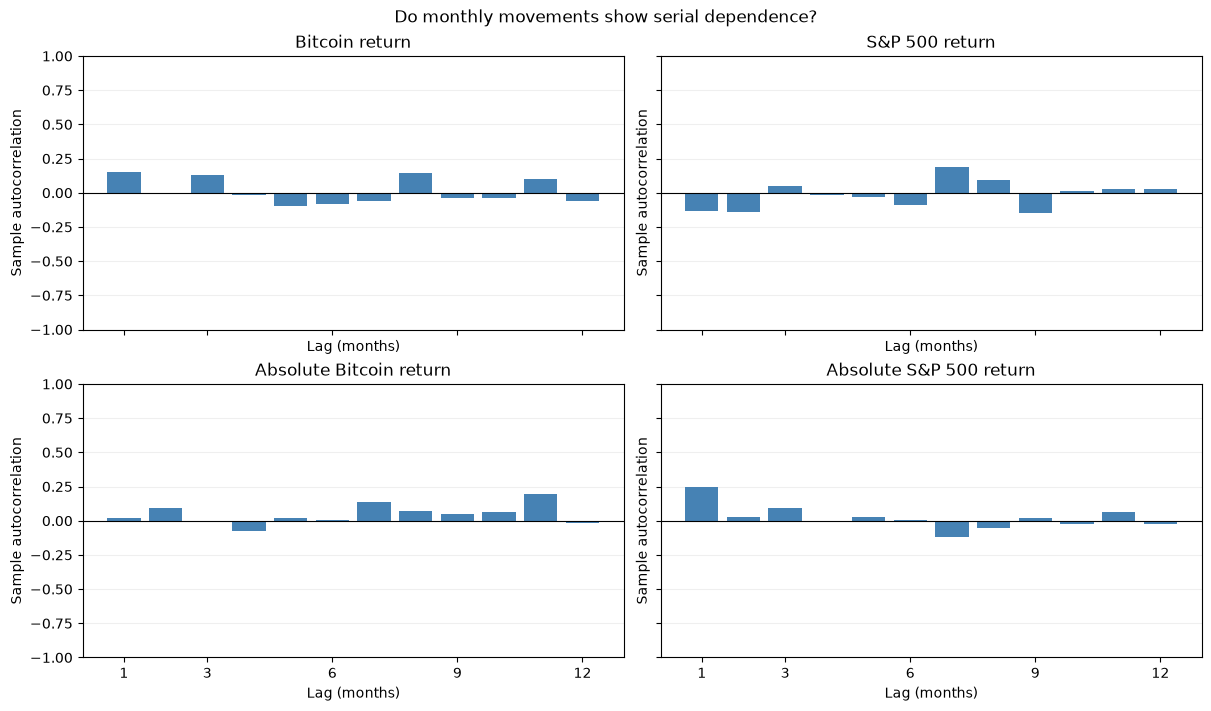

In [11]:
series_to_check = {
    "Bitcoin return": monthly["btc_return_pct"],
    "S&P 500 return": monthly["sp500_return_pct"],
    "Absolute Bitcoin return": monthly["btc_return_pct"].abs(),
    "Absolute S&P 500 return": monthly["sp500_return_pct"].abs()
}

lags = range(1, 13)

autocorrelations = pd.DataFrame({
    name: [series.autocorr(lag=lag) for lag in lags]
    for name, series in series_to_check.items()
})

autocorrelations.index = pd.Index(lags, name="Lag (months)")

display(autocorrelations.round(3))

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7),
    sharex=True, sharey=True,
    layout="constrained"
)

for ax, column in zip(axes.flat, autocorrelations.columns):
    ax.bar(
        autocorrelations.index,
        autocorrelations[column],
        color="steelblue"
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(column)
    ax.set_ylim(-1, 1)
    ax.set_xticks([1, 3, 6, 9, 12])
    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Sample autocorrelation")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("Do monthly movements show serial dependence?")
plt.show()

## Serial dependence diagnostics

We examine sample autocorrelations at lags of 1–12 months
for signed and absolute monthly returns.

Signed returns describe direction and size. Absolute returns
describe net movement magnitude and can reveal dependence
that is not apparent in signed returns.

These are exploratory diagnostics, not formal significance tests.
Each lag uses a different number of available observation pairs.
Small sample autocorrelations do not establish independence.

Absolute monthly returns are not a measure of all price
fluctuations within a month.

### Findings — serial dependence

Most sample autocorrelations at lags of 1–12 months
are small, with no clear recurring pattern.

The largest absolute coefficient is 0.246 for absolute
S&P 500 returns at lag 1. This suggests possible persistence
in net monthly movement magnitude, but does not establish it.

Bitcoin's signed returns have a lag-1 autocorrelation of 0.154.
Absolute Bitcoin returns show a coefficient of 0.194 at lag 11;
this isolated estimate does not establish annual seasonality.

We inspect 48 coefficients, so isolated peaks may arise by chance.
These diagnostics neither establish independence nor demonstrate
statistical significance.

Uncertainty estimates should account for possible serial dependence.

In [12]:
import numpy as np
import pandas as pd

paired = monthly[
    ["btc_return_pct", "sp500_return_pct"]
].dropna().sort_index()

# Check that dropping missing values has not created calendar gaps.
periods = paired.index.to_period("M")
expected = pd.period_range(periods.min(), periods.max(), freq="M")

if not periods.equals(expected):
    raise ValueError("The paired returns contain missing or duplicate months.")

values = paired.to_numpy()
n = len(values)
observed_r = np.corrcoef(values.T)[0, 1]

repetitions = 10_000
rows = []

for block_length in [3, 6, 12]:
    rng = np.random.default_rng(2026 + block_length)
    correlations = np.empty(repetitions)
    blocks_needed = int(np.ceil(n / block_length))

    for iteration in range(repetitions):
        # Sample overlapping blocks without wrapping the series.
        starts = rng.integers(
            0, n - block_length + 1,
            size=blocks_needed
        )

        indices = (
            starts[:, None] + np.arange(block_length)
        ).ravel()[:n]

        sample = values[indices]
        correlations[iteration] = np.corrcoef(sample.T)[0, 1]

    if not np.isfinite(correlations).all():
        raise ValueError("Some bootstrap correlations are undefined.")

    lower, upper = np.quantile(correlations, [0.025, 0.975])

    rows.append({
        "block_months": block_length,
        "observations": n,
        "observed_correlation": observed_r,
        "ci_95_lower": lower,
        "ci_95_upper": upper
    })

bootstrap_summary = pd.DataFrame(rows)
display(bootstrap_summary.round(3))

,block_months,observations,observed_correlation,ci_95_lower,ci_95_upper
0,3,105,0.4,0.203,0.570
1,6,105,0.4,0.196,0.565
2,12,105,0.4,0.184,0.574


## Correlation uncertainty — moving-block bootstrap

We resample paired Bitcoin and S&P 500 returns in consecutive
blocks. Within each block, the original time order is preserved.

For each block length, we generate 10,000 resamples and use
the 2.5th and 97.5th percentiles of their correlations as an
approximate 95% confidence interval.

Block lengths of 3, 6 and 12 months assess sensitivity to
this methodological choice. They are not separate independent
tests, and no block length is claimed to be optimal.

The method assumes a sufficiently stable underlying process
with short-range dependence. It does not resolve structural
changes, and the limited sample makes interval estimates uncertain.

These intervals concern association over the studied period,
not future returns or causation. No p-value is calculated here.

### Findings — uncertainty in the correlation estimate

The observed Pearson correlation is 0.400 across 105 paired
monthly returns.

Approximate 95% moving-block bootstrap intervals are:
- 3-month blocks: [0.203, 0.570].
- 6-month blocks: [0.196, 0.565].
- 12-month blocks: [0.184, 0.574].

All intervals exclude zero and have similar endpoints.
Under the bootstrap assumptions, this supports a positive
full-period association that is reasonably robust to the
three selected block lengths.

The intervals remain fairly wide, indicating uncertainty
about the strength of the association. Rolling correlations
also suggest that a single full-period estimate does not
describe every period equally well.

These exploratory results do not establish causation,
a constant relationship or forecasting ability. The bootstrap
assumes sufficient stability and does not eliminate concerns
about structural changes.

In [13]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "market_monthly_2018_2026.csv"

monthly.to_csv(
    output_path,
    index=True,
    index_label="month",
    encoding="utf-8"
)

print("Saved to:", output_path.resolve())
print("Rows:", len(monthly))
print("Columns:", len(monthly.columns))

Saved to: D:\Projects\FinancialMarketIntelligenceLab\data\processed\market_monthly_2018_2026.csv
Rows: 106
Columns: 15


## Saved analytical dataset

The merged monthly dataset is saved to:
`../data/processed/market_monthly_2018_2026.csv`.

It contains 106 months, from January 2018 to October 2026,
and 15 columns covering market values, search interest,
observation dates and counts, returns, and yield changes.

Original source files remain unchanged. No missing values
are imputed. The first month's returns and yield change
remain missing because December 2017 is outside the loaded data.

Daily calendar validation remains a separate task.
